In [1]:
%matplotlib widget

In [2]:
%%html
<style>
.cell-output-ipywidget-background {
   background-color: transparent !important;
}
.jp-OutputArea-output {
   background-color: transparent;
}  
</style>

In [3]:
import os
import sys
import numpy as np
import pandas as pd
import pickle
import tqdm
import matplotlib.pyplot as plt

from wombats.anomalies.increasing import *
from wombats.anomalies.invariant import *
from wombats.anomalies.decreasing import *

root = os.path.dirname(os.path.dirname(os.path.realpath('__file__')))
sys.path.insert(0, os.path.join(root, 'src'))

from detectors import detectors_dir
from models import models_dir
from dataset import dataset_dir


In [4]:
import cmasher as cmr
cmap_pd = cmr.get_sub_cmap('brg', 0.5, 1)
cmap_auc = cmr.get_sub_cmap('brg', 0, 1)

## Setup


In [5]:
anomalies_labels = [
    'GWN', 
    'Impulse', 
    'Step', 
    'Constant',  
    'GNN',
    'MixingGWN', 
    'MixingConstant',
    # 'SpectralAlteration', 
    # 'PrincipalSubspaceAlteration',
    'TimeWarping',
    'Clipping',
    'Dead-Zone'
]

anomalies_labels2 = [
    'SpectralAlteration', 
    'PrincipalSubspaceAlteration',
]

num_anomalies = 100

feature_detectors = ['MD', 'TV', 'ZC', 'pk-pk', 'energy']

detection_folder = '/srv/newpenny/dnn-cs/tsoc/results/TSOC/detection'

# Detector-specific configuration
# kernel = "rbf"   
kernel = "rbf"    
nu_list = [0.001, 0.01, 0.1]
neighbors_list = [5, 10, 20, 50]
estimators_list = [5, 10, 20, 50, 100, 200, 500, 1000]
sigma_list = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 0.2, 0.4, 0.6, 0.8, 1]

k_list = [1, 2, 4, 8, 16, 24, 32, 46]
order_list = [1, 2, 4, 8, 16, 24]

seed_train_list = [0, 1, 2, 3, 4]
opt_list = ['adam', 'sgd']
# bs_list = [32, 64, 128]
bs_list = [128]
alpha_list = [0.001, 0.01, 0.1, 0.25, 0.4, 0.5, 0.6, 0.75, 0.9, 0.99]
gamma_list= np.sort([0.0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
beta_list= np.sort([0.0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 0.0005, 0.005, 0.05, 0.5, 5])
# alpha_list = [0.001, 0.01, 0.1, 0.4, 0.5, 0.75, 0.9, 0.99]
min_delta_list = [1e-4, 1e-5]

# Anomalies configuration
seed_ko = 0
N_test = 10_000
# delta_list = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
delta_list = [0.001, 0.002, 0.005,0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 0.8]
# delta_list = [0.05, 0.1, 0.2, 0.5]

m_list = [16, 32]
mode_list = ['standard', 'rakeness']
ort_list = [True, False]
seed_mat_list = []

# Fixed parameters
n = 128
m = 32
mode = 'rakeness'
orthogonal = True
if m==48:
    seed_mat = 30808
elif m==32:
    seed_mat = 1651
elif m==16:
    seed_mat = 71864
seed_train = 0
opt = 'adam'
min_delta = 1e-5

In [6]:
def parse_neural_parameters(model_name, detector_type='TSOC'):
    model_name = model_name.split('.pth')[0]
    model_name = model_name.split(f'{detector_type}-')[1]
    params = model_name.split('_')
    param_dict = {}
    for param in params:
        key, value = param.split('=')
        # Attempt to convert to int, float, or keep as string
        if value.isdigit():
            param_dict[key] = int(value)
        else:
            try:
                param_dict[key] = float(value)
            except ValueError:
                # Special case for booleans
                if value.lower() in ['true', 'false']:
                    param_dict[key] = value.lower() == 'true'
                else:
                    param_dict[key] = value

    return param_dict

In [7]:
def load_ae_based_results(detector_mode, trained_models):
    seed_train_list = []
    index = pd.MultiIndex.from_product(
    [delta_list, m_list, seed_train_list, opt_list, bs_list, min_delta_list, beta_list, gamma_list],
      names=['delta', 'm', 'seedtrain', 'opt', 'bs', 'mind', 'beta', 'gamma'])
    results = pd.DataFrame(index=index, columns=[*anomalies_labels, *anomalies_labels2], dtype=np.float64)
    results.columns.name = 'anomalies'
    # for beta in beta_list:
    #     for gamma in gamma_list:
    for delta in delta_list:
        for trained_model in trained_models:
            params = parse_neural_parameters(trained_model, 'AE')
            trained_model = f"{trained_model.split('.pth')[0]}"
            idx = (delta, params['m'], params['seedtrain'], params['opt'], params['bs'], params['mind'], params['beta'], params['gamma'])
            # load results for all anomalies
            results_path = os.path.join(detection_folder, 'AE', detector_mode, 
                                        f'AUC_detector={trained_model}_delta={delta}_seedko={seed_ko}.pkl')
            
            if os.path.exists(results_path):
                data = pd.read_pickle(results_path)[anomalies_labels]
                results.loc[idx, anomalies_labels] = data

            # load results for covrariance alteration anomalies
            cov_alt_path = os.path.join(detection_folder, 'AE', detector_mode, 
                                        f'AUC_cov_alt_detector={trained_model}_delta={delta}_seedko={seed_ko}_na={num_anomalies}.pkl')
            if os.path.exists(cov_alt_path):
                data = pd.read_pickle(cov_alt_path)
                data = data.mean(axis=0)
                results.loc[idx, anomalies_labels2] = data
                
    return results

In [8]:
trained_models = os.listdir(os.path.join(f'{models_dir}AE'))

In [9]:
# 'self-assessment' 'MD_rtol=1e-6_noscaling' 'MD_scaling' 'norm_scaling' 'MD_clipevals_noscaling'
detection_SA = load_ae_based_results('self-assessment', trained_models)
detection_SA['mean'] = detection_SA.mean(axis=1)
detection_MD = load_ae_based_results('MD', trained_models)
detection_MD['mean'] = detection_MD.mean(axis=1)
# detection_MD = detection_MD.loc[detection_MD.index.get_level_values('beta').isin(beta_list)]
detection_OC = load_ae_based_results('OC', trained_models)
detection_OC['mean'] = detection_OC.mean(axis=1)
detection_MDhat = load_ae_based_results('MDhat', trained_models)
detection_MDhat['mean'] = detection_MDhat.mean(axis=1)
detection_AE = load_ae_based_results('autoencoder', trained_models)
detection_AE['mean'] = detection_AE.mean(axis=1)

In [10]:
detection_OC

anomalies                                                   GWN   Impulse  \
delta m  seedtrain opt  bs  mind         beta   gamma                       
0.001 16 0         adam 128 1.000000e-08 0.0000 0.0    0.500927  0.500151   
                                         0.0001 0.0    0.501351  0.500583   
                                         0.0010 0.0    0.501554  0.500477   
                                         0.0100 0.0    0.501072  0.500580   
                                         0.1000 0.0    0.511338  0.506684   
...                                                         ...       ...   
0.800 16 0         adam 128 1.000000e-08 0.0005 0.0    0.697982  0.670098   
                                         0.0050 0.0    0.808721  0.866775   
                                         0.0500 0.0    0.887181  0.981580   
                                         0.5000 0.0    0.996436  1.000000   
                                         5.0000 0.0    0.999879  1.000000   

anomalies                                                  Step  Constant  \
delta m  seedtrain opt  bs  mind         beta   gamma                       
0.001 16 0         adam 128 1.000000e-08 0.0000 0.0    0.503062  0.502180   
                                         0.0001 0.0    0.502476  0.501973   
                                         0.0010 0.0    0.502649  0.501679   
                                         0.0100 0.0    0.502840  0.501862   
                                         0.1000 0.0    0.501886  0.501448   
...                                                         ...       ...   
0.800 16 0         adam 128 1.000000e-08 0.0005 0.0    0.876399  0.864112   
                                         0.0050 0.0    0.881566  0.869055   
                                         0.0500 0.0    0.885836  0.869481   
                                         0.5000 0.0    0.919313  0.872561   
                                         5.0000 0.0    0.937605  0.903993   

anomalies                                                   GNN  MixingGWN  \
delta m  seedtrain opt  bs  mind         beta   gamma                        
0.001 16 0         adam 128 1.000000e-08 0.0000 0.0    0.500962   0.497375   
                                         0.0001 0.0    0.500943   0.497952   
                                         0.0010 0.0    0.501463   0.498680   
                                         0.0100 0.0    0.500901   0.497720   
                                         0.1000 0.0    0.510407   0.508833   
...                                                         ...        ...   
0.800 16 0         adam 128 1.000000e-08 0.0005 0.0    0.634029   0.149631   
                                         0.0050 0.0    0.700023   0.303982   
                                         0.0500 0.0    0.751054   0.515512   
                                         0.5000 0.0    0.915278   0.974727   
                                         5.0000 0.0    0.981280   0.999556   

anomalies                                              MixingConstant  \
delta m  seedtrain opt  bs  mind         beta   gamma                   
0.001 16 0         adam 128 1.000000e-08 0.0000 0.0          0.499072   
                                         0.0001 0.0          0.499197   
                                         0.0010 0.0          0.499128   
                                         0.0100 0.0          0.499168   
                                         0.1000 0.0          0.499715   
...                                                               ...   
0.800 16 0         adam 128 1.000000e-08 0.0005 0.0          0.266610   
                                         0.0050 0.0          0.259951   
                                         0.0500 0.0          0.271255   
                                         0.5000 0.0          0.307139   
                                         5.0000 0.0          0.272896   

anomalies                      

In [11]:
detection_MD.xs(16, level='m').xs(0, level='gamma')

anomalies                                          GWN       Impulse  \
delta seedtrain opt  bs  mind         beta                             
0.001 0         adam 128 1.000000e-08 0.0000  0.499629  4.998993e-01   
                                      0.0001  0.499486  4.997128e-01   
                                      0.0010  0.499188  4.997512e-01   
                                      0.0100  0.499490  4.997866e-01   
                                      0.1000  0.488930  4.939643e-01   
...                                                ...           ...   
0.800 0         adam 128 1.000000e-08 0.0005  0.349998  3.708653e-01   
                                      0.0050  0.244438  2.111585e-01   
                                      0.0500  0.158887  4.560897e-02   
                                      0.5000  0.005999  5.900000e-07   
                                      5.0000  0.000026  0.000000e+00   

anomalies                                         Step  Constant       GNN  \
delta seedtrain opt  bs  mind         beta                                   
0.001 0         adam 128 1.000000e-08 0.0000  0.498837  0.499016  0.499514   
                                      0.0001  0.498862  0.499184  0.499548   
                                      0.0010  0.498952  0.499022  0.499218   
                                      0.0100  0.498472  0.498862  0.499510   
                                      0.1000  0.498982  0.499202  0.490717   
...                                                ...       ...       ...   
0.800 0         adam 128 1.000000e-08 0.0005  0.115895  0.121249  0.391886   
                                      0.0050  0.118305  0.118116  0.331822   
                                      0.0500  0.124382  0.124975  0.284143   
                                      0.5000  0.097734  0.127259  0.108777   
                                      5.0000  0.019092  0.129858  0.025552   

anomalies                                     MixingGWN  MixingConstant  \
delta seedtrain opt  bs  mind         beta                                
0.001 0         adam 128 1.000000e-08 0.0000   0.501192        0.499875   
                                      0.0001   0.500927        0.499829   
                                      0.0010   0.500577        0.499719   
                                      0.0100   0.501286        0.499909   
                                      0.1000   0.490487        0.499570   
...                                                 ...             ...   
0.800 0         adam 128 1.000000e-08 0.0005   0.780429        0.516481   
                                      0.0050   0.632579        0.500203   
                                      0.0500   0.440451        0.489245   
                                      0.5000   0.023430        0.466730   
                                      5.0000   0.000008        0.474041   

anomalies                                     TimeWarping  Clipping  \
delta seedtrain opt  bs  mind         beta                            
0.001 0         adam 128 1.000000e-08 0.0000     0.501552  0.540459   
                                      0.0001     0.502036  0.537893   
                                      0.0010     0.502057  0.544587   
                                      0.0100     0.501992  0.548096   
                                      0.1000     0.503269  0.566622   
...                                                   ...       ...   
0.800 0         adam 128 1.000000e-08 0.0005     0.516439  0.999313   
                                      0.0050     0.540097  0.999304   
                                      0.0500     0.547434  0.999287   
                                      0.5000     0.563774  0.998853   
                                      5.0000     0.552293  0.992230   

anomalies                                     Dead-Zone  SpectralAlteration  \
delta seedtrain opt  bs  mind         beta                           

In [12]:
detection_OC.isna().sum().sum()

0

## Reconstruction

In [13]:
reconstruction_folder = '/srv/newpenny/dnn-cs/tsoc/results/TSOC/reconstruction'

In [14]:
decoder_type = 'AE'
trained_models = os.listdir(os.path.join(f'{models_dir}{decoder_type}'))
trained_models

['AE-N=2000000_n=128_m=16_fs=256_hr=60-100_isnr=35_beta=0_gamma=0_epochs=1000_bs=128_opt=adam_lr=0.001_tf=0.9_minlr=1e-05_p=40_mind=1e-08_seeddata=11_seedtrain=3.pth',
 'AE-N=2000000_n=128_m=48_fs=256_hr=60-100_isnr=35_beta=0.0_gamma=0.001_epochs=1000_bs=128_opt=adam_lr=0.001_tf=0.9_minlr=1e-05_p=40_mind=1e-08_seeddata=11_seedtrain=0.pth',
 'AE-N=2000000_n=128_m=48_fs=256_hr=60-100_isnr=35_beta=0.0_gamma=1.0_epochs=1000_bs=128_opt=adam_lr=0.001_tf=0.9_minlr=1e-05_p=40_mind=1e-08_seeddata=11_seedtrain=0.pth',
 'AE-N=2000000_n=128_m=48_fs=256_hr=60-100_isnr=35_beta=0.0_gamma=0.01_epochs=1000_bs=128_opt=adam_lr=0.001_tf=0.9_minlr=1e-05_p=40_mind=1e-08_seeddata=11_seedtrain=0.pth',
 'AE-N=2000000_n=128_m=48_fs=256_hr=60-100_isnr=35_beta=0.0_gamma=0.1_epochs=1000_bs=128_opt=adam_lr=0.001_tf=0.9_minlr=1e-05_p=40_mind=1e-08_seeddata=11_seedtrain=0.pth',
 'AE-N=2000000_n=128_m=16_fs=256_hr=60-100_isnr=35_beta=0.0_gamma=1.0_epochs=1000_bs=128_opt=adam_lr=0.001_tf=0.9_minlr=1e-05_p=40_mind=1e-08

In [15]:
def parse_parameters(model_name, decoder_type='TSOC', extension='.pth'):
    model_name = model_name.split(extension)[0]
    model_name = model_name.split(f'{decoder_type}-')[1]
    params = model_name.split('_')
    param_dict = {}
    for param in params:
        key, value = param.split('=')
        # Attempt to convert to int, float, or keep as string
        if value.isdigit():
            param_dict[key] = int(value)
        else:
            try:
                param_dict[key] = float(value)
            except ValueError:
                # Special case for booleans
                if value.lower() in ['true', 'false']:
                    param_dict[key] = value.lower() == 'true'
                else:
                    param_dict[key] = value

    return param_dict

In [16]:
m_list = [16, 32, 48, 64]
seed_train_list = [0, 1, 2, 3]
seed_train_list = [0]
opt_list = ['adam']
bs_list = [128]
min_delta_list = [1e-8]
# gamma_list= np.sort([0.0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
# beta_list2 = np.sort([0.0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])

index = pd.MultiIndex.from_product(
    [m_list, seed_train_list, opt_list, bs_list, min_delta_list, beta_list, gamma_list],
      names=['m', 'seedtrain', 'opt', 'bs', 'mind', 'beta', 'gamma'])
reconstruction = pd.DataFrame(index=index, columns=['RSNR'], dtype=np.float64)

for model_name in trained_models:
    params = parse_parameters(model_name, decoder_type)
    results_path = os.path.join(reconstruction_folder, f"{model_name.split('.pth')[0]}.pkl")
    if os.path.exists(results_path):
        result = pd.read_pickle(results_path)
        reconstruction.loc[params['m'], params['seedtrain'], params['opt'], params['bs'], params['mind'], params['beta'], params['gamma']] = result



In [17]:
m = 16

In [18]:
reconstruction_sub = reconstruction.xs(m, level='m').xs(0, level='gamma').xs(0, level='seedtrain').xs(min_delta_list[0], level='mind').xs(128, level='bs').xs('adam', level='opt')
reconstruction_sub_beta = reconstruction_sub.sort_index().loc[beta_list]

reconstruction_sub = reconstruction.xs(m, level='m').xs(0, level='beta').xs(0, level='seedtrain').xs(min_delta_list[0], level='mind').xs(128, level='bs').xs('adam', level='opt')
reconstruction_sub_gamma = reconstruction_sub.sort_index().loc[gamma_list]


In [19]:
reconstruction_sub_beta

,RSNR
beta,
0.0000,34.834793
0.0001,34.842857
0.0005,34.762341
0.0010,34.695812
0.0050,34.535473
0.0100,34.435299
0.0500,34.035740
0.1000,33.853943
0.5000,33.484562


In [86]:
detection_sub = (1-detection_SA[:-1]).xs(m, level='m').xs(0, level='gamma').xs(0.05, level='beta')
detection_sub

,,,,anomalies,GWN,Impulse,Step,Constant,GNN,MixingGWN,MixingConstant,TimeWarping,Clipping,Dead-Zone,SpectralAlteration,PrincipalSubspaceAlteration,mean
delta,seedtrain,opt,bs,mind,,,,,,,,,,,,,
0.001,0,adam,128,1.000000e-08,0.822807,0.880569,0.688985,0.502996,0.688745,0.822445,0.502613,0.501423,0.695971,0.851039,0.858770,0.795931,0.717691
0.002,0,adam,128,1.000000e-08,0.916081,0.962352,0.793786,0.506100,0.733295,0.914872,0.505283,0.504059,0.695971,0.946172,0.909374,0.886689,0.772836
0.005,0,adam,128,1.000000e-08,0.980145,0.993276,0.919246,0.515597,0.791140,0.979158,0.513218,0.507686,0.824564,0.992670,0.960562,0.963682,0.828412
0.010,0,adam,128,1.000000e-08,0.993919,0.996827,0.971223,0.531539,0.837237,0.993488,0.525919,0.508410,0.824564,0.996441,0.983770,0.987857,0.845933
0.020,0,adam,128,1.000000e-08,0.997313,0.998087,0.990801,0.563201,0.882909,0.997189,0.548576,0.509688,0.851950,0.997840,0.994449,0.995868,0.860656
0.050,0,adam,128,1.000000e-08,0.998835,0.999357,0.996984,0.649084,0.933727,0.998795,0.597916,0.530371,0.864184,0.999226,0.998601,0.998570,0.880471
0.100,0,adam,128,1.000000e-08,0.999513,0.999891,0.998288,0.750918,0.961727,0.999477,0.637133,0.556213,0.893641,0.999718,0.999333,0.999323,0.899598
0.200,0,adam,128,1.000000e-08,0.999862,0.999991,0.999189,0.862797,0.980005,0.999830,0.670634,0.608508,0.974847,0.999847,0.999637,0.999723,0.924572
0.500,0,adam,128,1.000000e-08,0.999989,1.000000,0.999861,0.967647,0.992388,0.999973,0.784922,0.731609,0.997599,0.999783,0.999843,0.999932,0.956129


In [74]:
detection_sub = (detection_OC[:-1]).xs(m, level='m').xs(0, level='gamma').groupby('beta').mean()

In [75]:
detection_sub['mean']

beta
0.0000       0.476793
0.0001       0.482089
0.0005       0.478778
0.0010       0.490322
0.0050       0.498738
0.0100       0.479713
0.0500       0.522366
0.1000       0.589036
0.5000       0.620183
1.0000       0.694951
5.0000       0.634226
10.0000      0.617075
100.0000     0.608390
1000.0000    0.579505
Name: mean, dtype: float64

In [56]:
reconstruction_sub_beta

,RSNR
beta,
0.0000,34.834793
0.0001,34.842857
0.0005,34.762341
0.0010,34.695812
0.0050,34.535473
0.0100,34.435299
0.0500,34.035740
0.1000,33.853943
0.5000,33.484562


In [32]:
detection_sub = (1-detection_MD).xs(m, level='m').xs(0, level='gamma').groupby('delta').max()
detection_sub_MD_beta = detection_sub.sort_index()['mean']
detection_sub_MD_beta

delta
0.001    0.528984
0.002    0.553251
0.005    0.608652
0.010    0.656290
0.020    0.701831
0.050    0.742915
0.100    0.763122
0.200    0.782915
0.500    0.788299
0.800    0.776519
Name: mean, dtype: float64

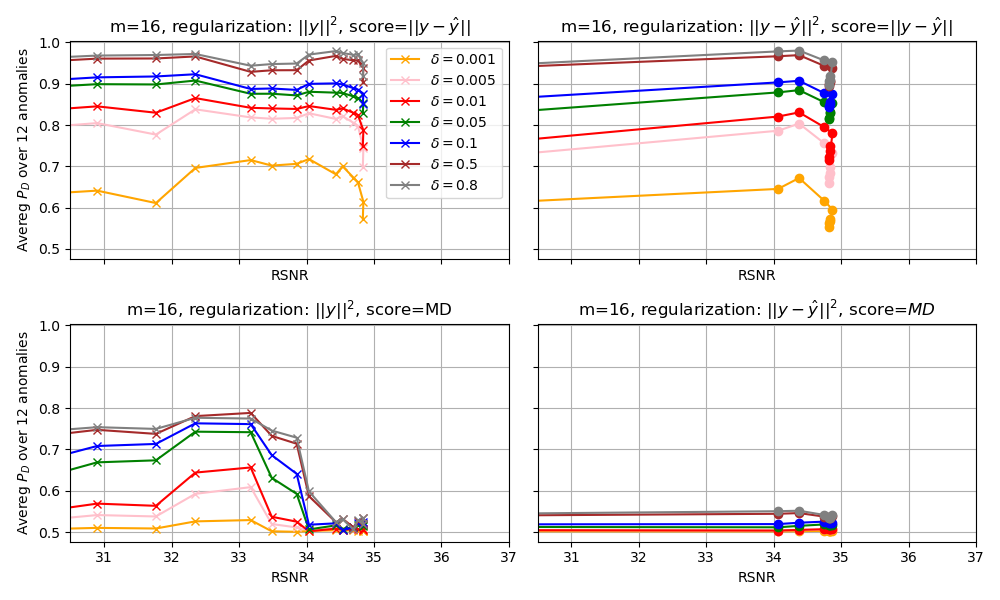

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)

for delta, color in zip([0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 0.8], ['orange', 'pink', 'r', 'g', 'b', 'brown', 'gray']):
    # detection_sub = np.abs(detection_SA.xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean() - 0.5) + 0.5
    detection_sub = (1-detection_SA).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_sub_SA_beta = detection_sub.sort_index()['mean']

    detection_sub = (1-detection_SA).xs(m, level='m').xs(0, level='beta').xs(delta, level='delta').groupby('gamma').mean()
    detection_sub_SA_gamma = detection_sub.sort_index()['mean']

    
    ax[0, 0].plot(reconstruction_sub_beta.values, detection_sub_SA_beta.values, marker='x', label=f'$\delta=${delta}', c=color)
    ax[0, 0].set(xlabel='RSNR', ylabel='Avereg $P_D$ over 12 anomalies')
    ax[0, 0].set(title=f'm={m}, regularization: $||y||^2$, score=$||y-\hat y||$')
    ax[0, 0].grid('on')
    ax[0, 0].legend()

    ax[0, 1].plot(reconstruction_sub_gamma.values, detection_sub_SA_gamma.values, marker='o', c=color)
    ax[0, 1].set(xlabel='RSNR')
    ax[0, 1].set(title=f'm={m}, regularization: $||y - \hat y||^2$, score=$||y-\hat y||$')
    ax[0, 1].grid('on')
    

    detection_sub = np.abs(detection_MD.xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean() - 0.5) + 0.5
    detection_sub_MD_beta = detection_sub.sort_index()['mean']
    detection_sub = np.abs(detection_MD.xs(m, level='m').xs(0, level='beta').xs(delta, level='delta').groupby('gamma').mean() - 0.5) + 0.5
    detection_sub_MD_gamma = detection_sub.sort_index()['mean']

    ax[1, 0].plot(reconstruction_sub_beta.values, detection_sub_MD_beta.values, marker='x', c=color)
    ax[1, 0].set(xlabel='RSNR', ylabel='Avereg $P_D$ over 12 anomalies')
    ax[1, 0].set(title=f'm={m}, regularization: $||y||^2$, score=MD')
    ax[1, 0].grid('on')

    ax[1, 1].plot(reconstruction_sub_gamma.values, detection_sub_MD_gamma.values, marker='o', c=color)
    ax[1, 1].set(xlabel='RSNR', xlim=[30.5, 37])
    ax[1, 1].set(title=f'm={m}, regularization: $||y - \hat y||^2$, score=$MD$')
    ax[1, 1].grid('on')
    

    fig.tight_layout()

In [21]:
reconstruction_sub_beta

,RSNR
beta,
0.0000,34.834793
0.0001,34.842857
0.0005,34.762341
0.0010,34.695812
0.0050,34.535473
0.0100,34.435299
0.0500,34.035740
0.1000,33.853943
0.5000,33.484562


ValueError: x and y must have same first dimension, but have shapes (14, 1) and (9,)

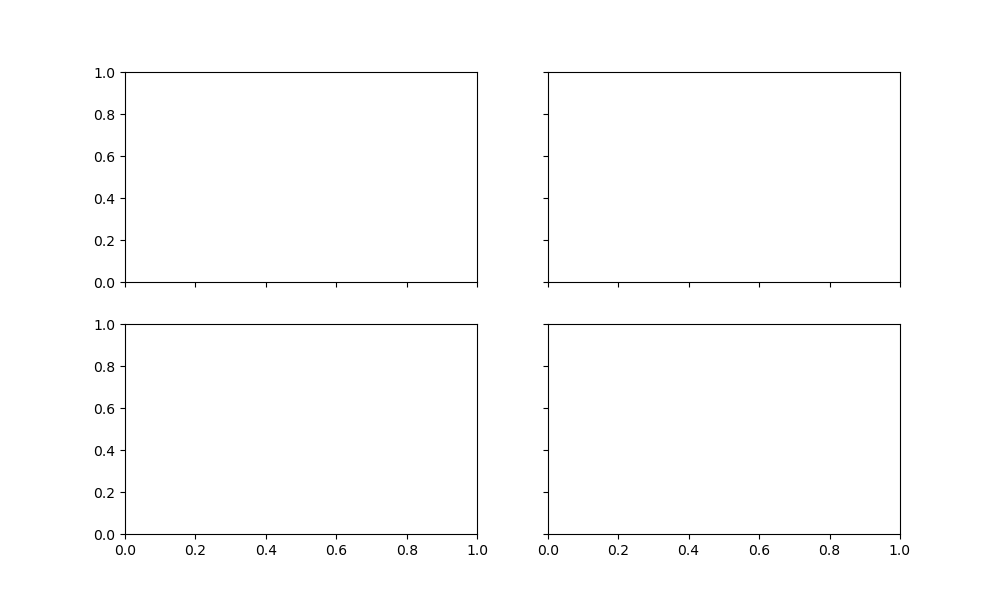

In [22]:
fig, ax = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)

for delta, color in zip([0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 0.8], ['orange', 'pink', 'r', 'g', 'b', 'brown', 'gray']):
    for i, m in enumerate([32, 16]):
        reconstruction_sub = reconstruction.xs(m, level='m').xs(0, level='gamma').xs(0, level='seedtrain').xs(min_delta_list[0], level='mind').xs(128, level='bs').xs('adam', level='opt')
        reconstruction_sub_beta = reconstruction_sub.sort_index().loc[beta_list]
        
        detection_sub = (1-detection_SA).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
        detection_sub_SA_beta = detection_sub.sort_index()['mean']

        detection_sub = (1-detection_MD).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
        detection_sub_MD_beta = detection_sub.sort_index()['mean']

        
        ax[i, 0].plot(reconstruction_sub_beta.values, detection_sub_SA_beta.values, marker='x', label=f'$\delta=${delta}', c=color)
        ax[i, 0].set(xlabel='RSNR', ylabel='Avereg $P_D$ over 12 anomalies')
        ax[i, 0].set(title=f'm={m}, regularization: $||y||^2$, score=$||y-\hat y||$')
        ax[i, 0].grid('on')
        ax[i, 0].legend()

        ax[i, 1].plot(reconstruction_sub_beta.values, detection_sub_MD_beta.values, marker='x', label=f'$\delta=${delta}', c=color)
        ax[i, 1].set(xlabel='RSNR')
        ax[i, 1].set(title=f'm={m}, regularization: $||y||^2$, score=MD')
        ax[i, 1].grid('on')

        ax[0, 0].set(xlim=[32.5, 36])

    fig.tight_layout()

ValueError: x and y must have same first dimension, but have shapes (13, 1) and (8,)

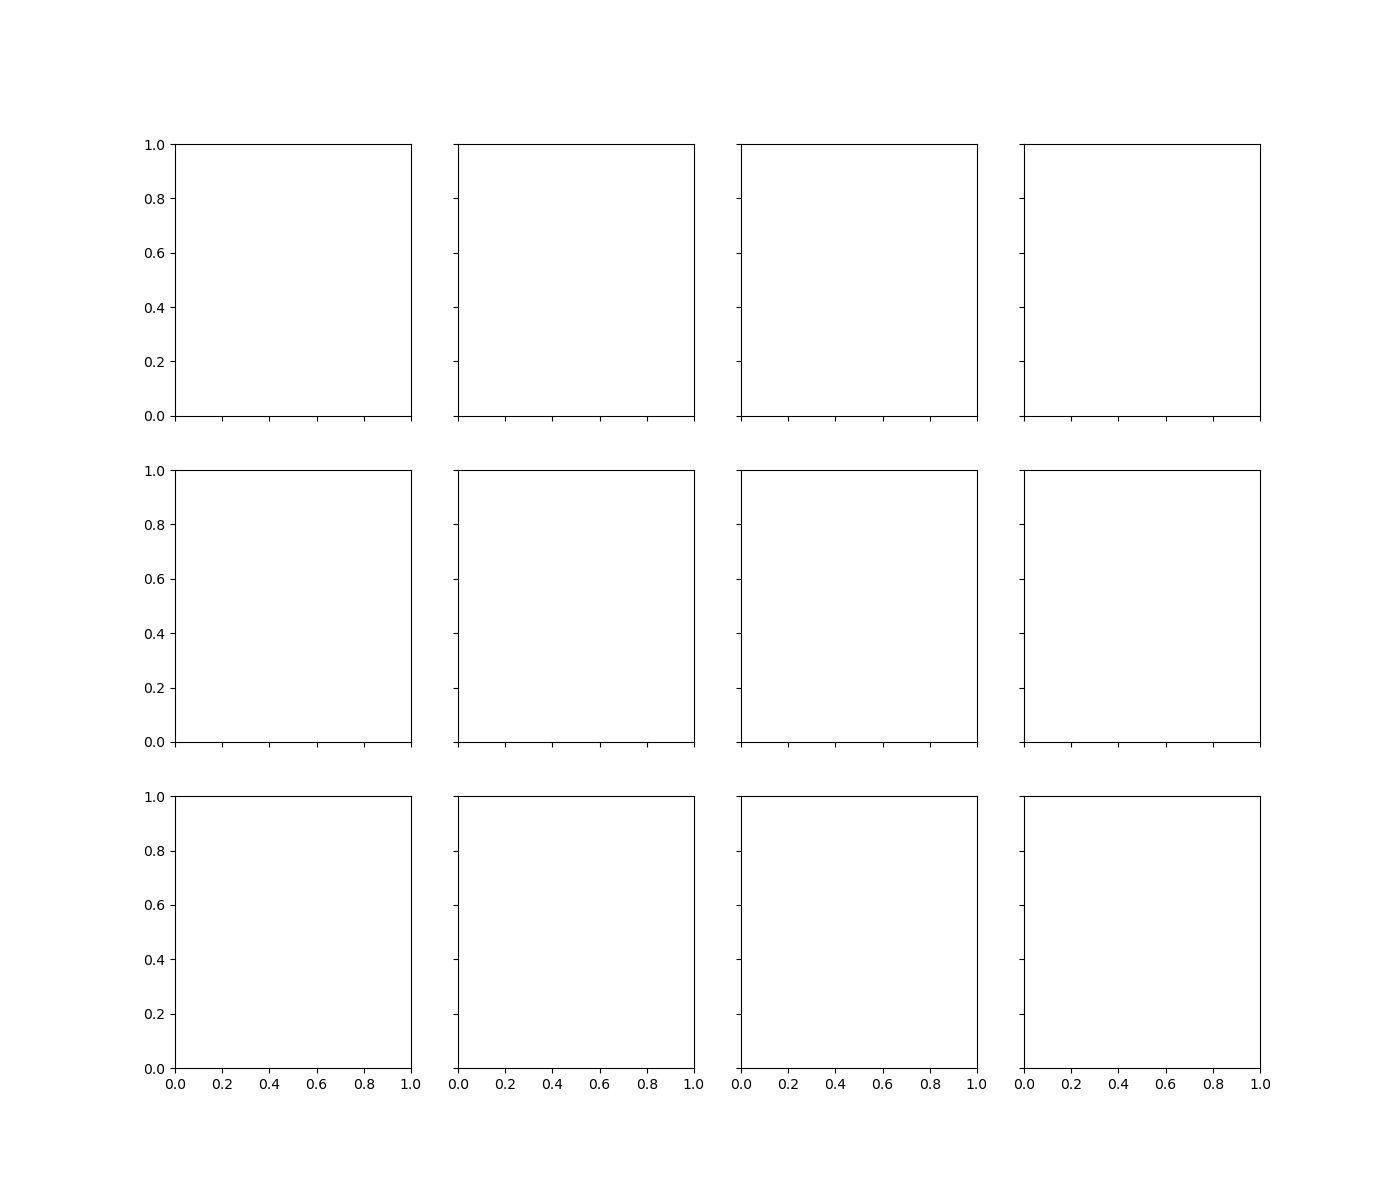

In [23]:
anomalies = list(detection_SA.columns)[:-1]
delta_list2 = [0.002, 0.005]
per_row = 4
fig, ax = plt.subplots(len(anomalies)//per_row, per_row, figsize=(14, 12), sharex=True, sharey=True)
for delta, color in zip(delta_list2, [
    # 'pink',
      'orange', 'r',
    #   'brown'
      ]):
    detection_SA_sub = (1-detection_SA).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_MD_sub = (1-detection_MD).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    for i, anomaly in enumerate(anomalies):
        row, column = i//per_row, i%per_row
        ax[row, column].plot(reconstruction_sub_beta.values[1:], detection_SA_sub[anomaly].values[1:], marker='x', label=f'$\delta=${delta}', c=color)
        ax[row, column].plot(reconstruction_sub_beta.values[1:], detection_MD_sub[anomaly].values[1:], marker='o', c=color, linestyle='dashed')
        ax[row, column].axvline(reconstruction_sub_beta.values[0], c='k', linestyle='dotted')
        ax[row, column].axhline(detection_MD_sub[anomaly].values[0], c=color, linestyle='dashdot')
        ax[row, column].axhline(detection_SA_sub[anomaly].values[0], c=color, linestyle='dotted')
        # ax[0, 0].set(xlabel='RSNR', ylabel='Avereg $P_D$ over 12 anomalies')
        ax[row, column].set(title=f'{anomaly}', xlim=[33, reconstruction_sub_beta.values[0]+0.2])
        ax[row, column].grid('on')
        ax[row, column].legend()

    fig.tight_layout()

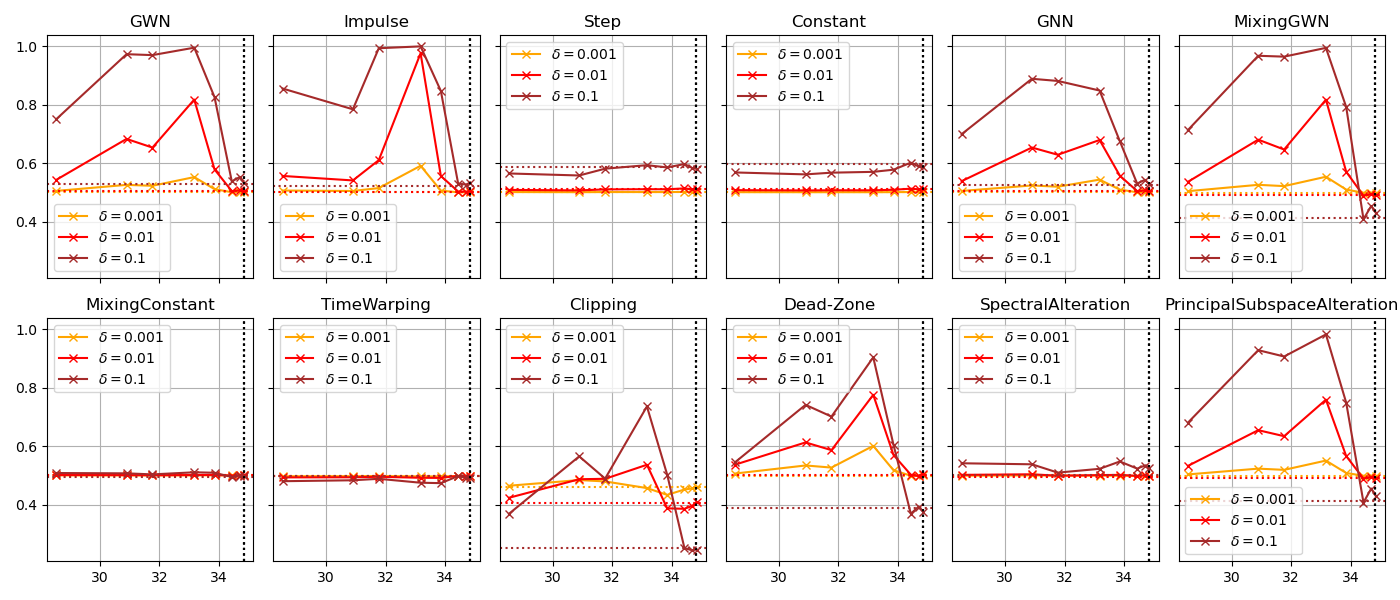

In [36]:
anomalies = list(detection_MD.columns)[:-1]
delta_list2 = [0.001, 0.01, 0.1]

fig, ax = plt.subplots(2, len(anomalies)//2, figsize=(14, 6), sharex=True, sharey=True)
for delta, color in zip(delta_list2, ['orange', 'r', 'brown']):
    detection_MD_sub = (1-detection_MD).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    for i, anomaly in enumerate(anomalies):
        ax[i//6, i%6].plot(reconstruction_sub_beta.values[1:], detection_MD_sub[anomaly].values[1:], marker='x', label=f'$\delta=${delta}', c=color)
        ax[i//6, i%6].axvline(reconstruction_sub_beta.values[0], c='k', linestyle='dotted')
        ax[i//6, i%6].axhline(detection_MD_sub[anomaly].values[0], c=color, linestyle='dotted')
        # ax[0, 0].set(xlabel='RSNR', ylabel='Avereg $P_D$ over 12 anomalies')
        ax[i//6, i%6].set(title=f'{anomaly}')
        ax[i//6, i%6].grid('on')
        ax[i//6, i%6].legend()

    fig.tight_layout()

## Grafici paper

In [20]:
m = 16

In [21]:
reconstruction_sub

,RSNR
gamma,
0.0000,34.834793
0.0001,34.831230
0.0010,34.824150
0.0100,34.825092
0.1000,34.870155
1.0000,34.747604
10.0000,34.375519
100.0000,34.064468
1000.0000,16.683529


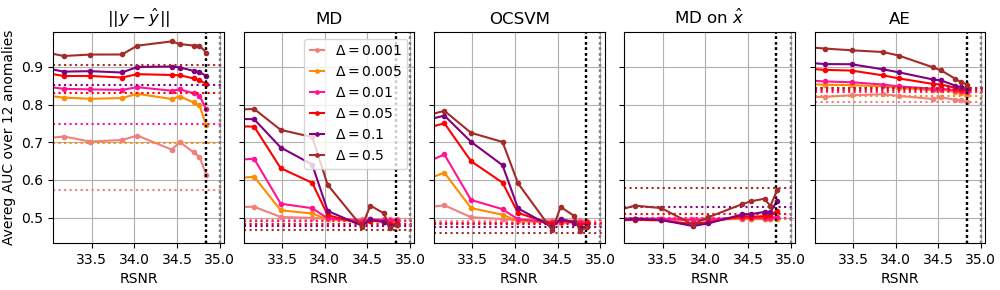

In [22]:
fig, ax = plt.subplots(1, 5, figsize=(10, 2.9), sharex=True, sharey=True)

for delta, color in zip([0.001, 0.005, 0.01, 0.05, 0.1, 0.5], ['lightcoral', 'darkorange', 'deeppink', 'r', 'purple', 'brown']):
    reconstruction_sub = reconstruction.xs(m, level='m').xs(0, level='gamma').xs(0, level='seedtrain').xs(min_delta_list[0], level='mind').xs(128, level='bs').xs('adam', level='opt')
    reconstruction_sub_beta = reconstruction_sub.sort_index().loc[beta_list]
    
    detection_sub = (1-detection_SA).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_sub_SA_beta = detection_sub.sort_index()['mean']

    detection_sub = (1-detection_MD).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_sub_MD_beta = detection_sub.sort_index()['mean']

    detection_sub = (detection_OC).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_sub_OC_beta = detection_sub.sort_index()['mean']

    detection_sub = (1-detection_MDhat).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_sub_MDhat_beta = detection_sub.sort_index()['mean']

    detection_sub = (1-detection_AE).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_sub_AE_beta = detection_sub.sort_index()['mean']

    ax[0].axvline(reconstruction_sub_beta.values[0], c='k', linestyle='dotted')
    ax[0].axvline(35, c='gray', linestyle='dotted')
    ax[0].axhline(detection_sub_SA_beta.values[0], c=color, linestyle='dotted')
    ax[0].plot(reconstruction_sub_beta.values[1:], detection_sub_SA_beta.values[1:], marker='.', label=f'$\Delta=${delta}', c=color)
    ax[0].set(xlabel='RSNR', ylabel='Avereg AUC over 12 anomalies')
    # ax[0].set(title=f'CR={n//m}, regularization: $||y||^2$, score: $||y-\hat y||$')
    ax[0].set(title=f'$||y-\hat y||$')
    ax[0].grid('on')
    # ax[0].legend()
    
    ax[1].axvline(reconstruction_sub_beta.values[0], c='k', linestyle='dotted')
    ax[1].axvline(35, c='gray', linestyle='dotted')
    ax[1].axhline(detection_sub_MD_beta.values[0], c=color, linestyle='dotted')
    ax[1].plot(reconstruction_sub_beta.values[1:], detection_sub_MD_beta.values[1:], marker='.',
                label=f'$\Delta=${delta}',
                 c=color
               )
    ax[1].set(xlabel='RSNR')
    # ax[1].set(title=f'CR={n//m}, regularization: $||y||^2$, score: MD')
    ax[1].set(title=f'MD')
    ax[1].grid('on')
    ax[1].legend(loc='upper right', bbox_to_anchor=(1, 1),
                  # ncol=2, 
                  markerscale=0.8, columnspacing=0.8, handlelength=1
                  )

    ax[2].axvline(reconstruction_sub_beta.values[0], c='k', linestyle='dotted')
    ax[2].axvline(35, c='gray', linestyle='dotted')
    ax[2].axhline(detection_sub_OC_beta.values[0], c=color, linestyle='dotted')
    ax[2].plot(reconstruction_sub_beta.values[1:], detection_sub_OC_beta.values[1:], marker='.',
                # label=f'$\Delta=${delta}',
                  c=color
                )
    ax[2].set(xlabel='RSNR')
    # ax[2].set(title=f'CR={n//m}, regularization: $||y||^2$, score: OCSVM')
    ax[2].set(title=f'OCSVM')
    ax[2].grid('on')

    ax[3].axvline(reconstruction_sub_beta.values[0], c='k', linestyle='dotted')
    ax[3].axvline(35, c='gray', linestyle='dotted')
    ax[3].axhline(detection_sub_MDhat_beta.values[0], c=color, linestyle='dotted')
    ax[3].plot(reconstruction_sub_beta.values[1:], detection_sub_MDhat_beta.values[1:], marker='.',
                # label=f'$\Delta=${delta}',
                  c=color
                )
    ax[3].set(xlabel='RSNR')
    # ax[2].set(title=f'CR={n//m}, regularization: $||y||^2$, score: OCSVM')
    ax[3].set(title='MD on $\hat{x}$')
    ax[3].grid('on')

    ax[4].axvline(reconstruction_sub_beta.values[0], c='k', linestyle='dotted')
    ax[4].axvline(35, c='gray', linestyle='dotted')
    ax[4].axhline(detection_sub_AE_beta.values[0], c=color, linestyle='dotted')
    ax[4].plot(reconstruction_sub_beta.values[1:], detection_sub_AE_beta.values[1:], marker='.',
                # label=f'$\Delta=${delta}',
                  c=color
                )
    ax[4].set(xlabel='RSNR')
    # ax[2].set(title=f'CR={n//m}, regularization: $||y||^2$, score: OCSVM')
    ax[4].set(title=f'AE')
    ax[4].grid('on')


    ax[0].set(xlim=[33.05, 35.05])
    
    # fig.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=len([0.001, 0.005, 0.01, 0.05, 0.1, 0.5]))
    # fig.legend(loc='upper center', bbox_to_anchor=(0, 2.08), ncol=3)
    fig.subplots_adjust(wspace=0.2, hspace=0.1)
    fig.tight_layout(pad=0.9)
    fig.savefig(os.path.join('..', 'eusipco_results', 'ECG_average_results.pdf'))

In [23]:
detection_sub_SA_beta

beta
0.0000       0.905115
0.0001       0.937716
0.0005       0.956375
0.0010       0.956438
0.0050       0.960136
0.0100       0.967302
0.0500       0.956129
0.1000       0.932684
0.5000       0.932492
1.0000       0.928649
5.0000       0.965980
10.0000      0.961042
100.0000     0.960656
1000.0000    0.939891
Name: mean, dtype: float64

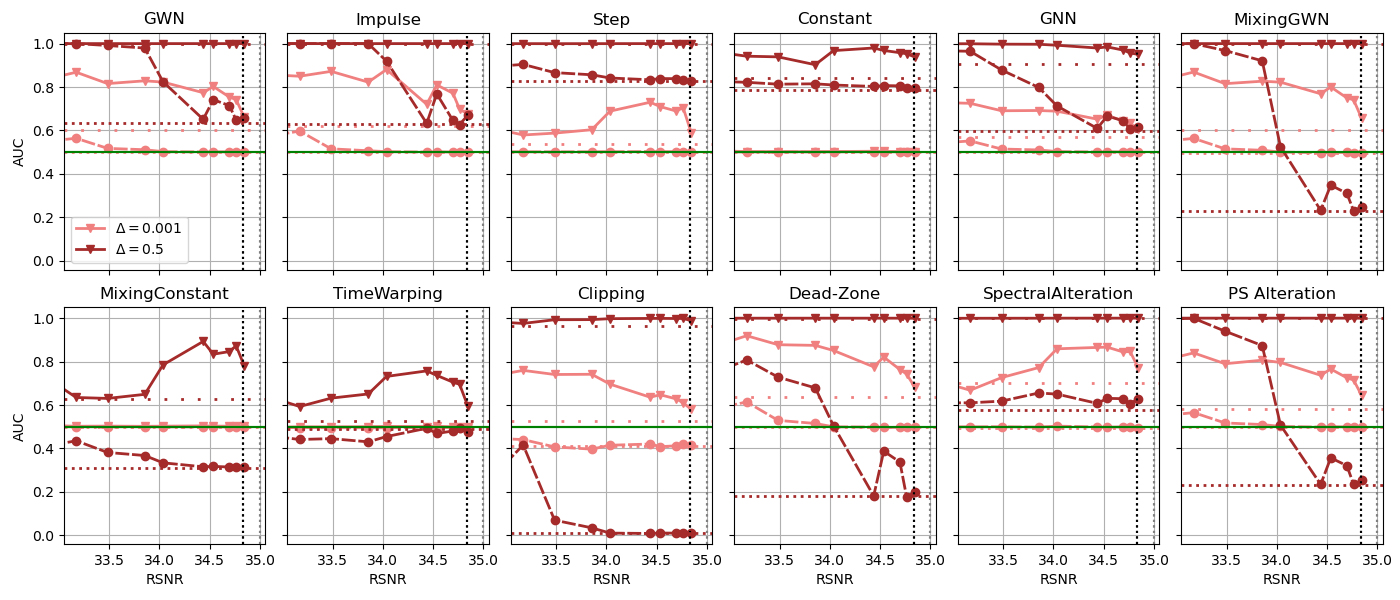

In [24]:
linewidth=2
anomalies = list(detection_SA.columns)[:-1]
delta_list2 = [0.001, 0.5]
per_row = 6
fig, ax = plt.subplots(len(anomalies)//per_row, per_row, figsize=(14, 6), sharex=True, sharey=True)
for delta, color in zip(delta_list2, [
    'lightcoral',
      # 'orange', 
      # 'r',
      'brown'
      ]):
    detection_SA_sub = (1-detection_SA).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_MD_sub = (detection_OC).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    for i, anomaly in enumerate(anomalies):
        row, column = i//per_row, i%per_row
        ax[row, column].plot(reconstruction_sub_beta.values[1:], detection_SA_sub[anomaly].values[1:], marker='v', label=f'$\Delta=${delta}', c=color, linewidth=linewidth)
        ax[row, column].plot(reconstruction_sub_beta.values[1:], detection_MD_sub[anomaly].values[1:], marker='o', c=color, linestyle=(0, (5, 1)), linewidth=linewidth)
        ax[row, column].axvline(reconstruction_sub_beta.values[0], c='k', linestyle='dotted',
                                #  label='RSNR $\lambda=0$'
                                 )
        ax[row, column].axvline(35, c='gray', linestyle='dotted',
                                #  label='ISNR'
                                 )
        ax[row, column].axhline(0.5, c='g', linestyle='solid',
                                #  label='Random detector'
                                 )
        ax[row, column].axhline(detection_MD_sub[anomaly].values[0], c=color, linestyle='dotted', linewidth=linewidth)
        ax[row, column].axhline(detection_SA_sub[anomaly].values[0], c=color, linestyle=(0, (1, 5)), linewidth=linewidth)
        # ax[0, 0].set(xlabel='RSNR', ylabel='Avereg $P_D$ over 12 anomalies')
        if anomaly == 'PrincipalSubspaceAlteration':
           anomaly_label = 'PS Alteration'
        else:
           anomaly_label = f'{anomaly}'
        ax[row, column].set(title=f'{anomaly_label}', xlim=[33.05, 35.05])
        ax[row, column].grid('on')

        if column == 0:
          ax[row, column].set(ylabel='AUC')
        if row == 1:
          ax[row, column].set(xlabel='RSNR')
 

ax[0, 0].legend()

fig.subplots_adjust(wspace=0.2, hspace=0.1)
fig.tight_layout(pad=0.9)

fig.savefig(os.path.join('..', 'eusipco_results', 'ECG_peranomaly_results.pdf'))


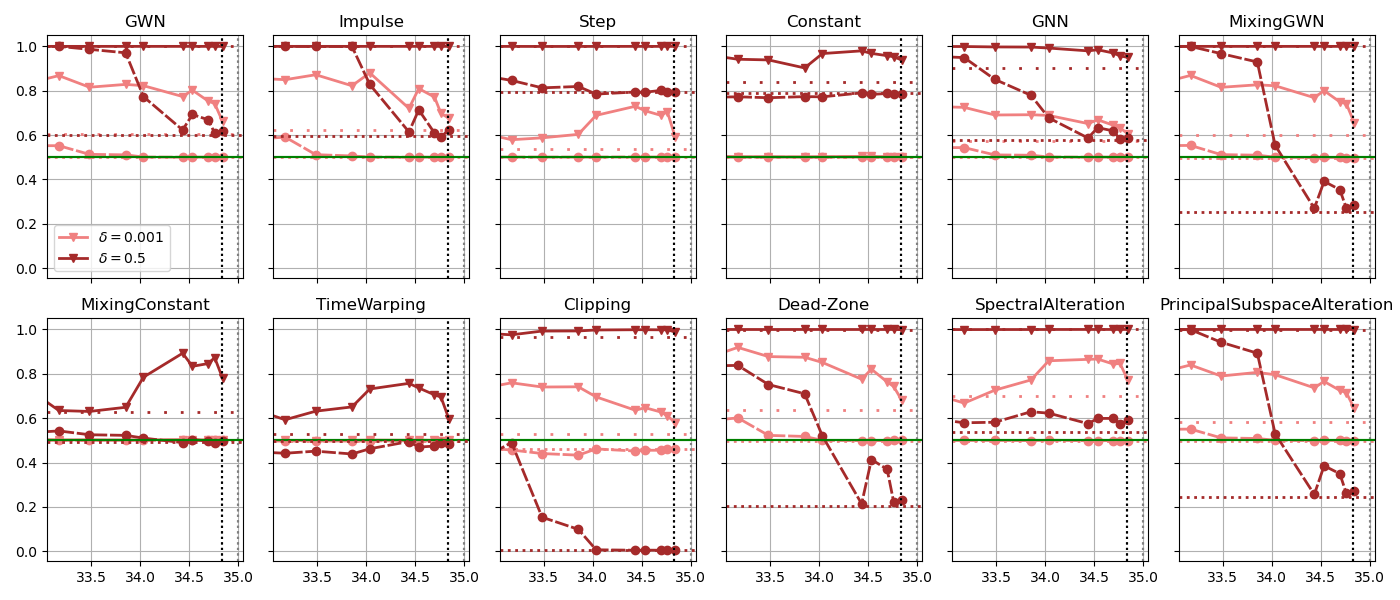

In [ ]:
linewidth=2
anomalies = list(detection_SA.columns)[:-1]
delta_list2 = [0.001, 0.5]
per_row = 6
fig, ax = plt.subplots(len(anomalies)//per_row, per_row, figsize=(14, 6), sharex=True, sharey=True)
for delta, color in zip(delta_list2, [
    'lightcoral',
      # 'orange', 
      # 'r',
      'brown'
      ]):
    detection_SA_sub = (1-detection_SA).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_MD_sub = (1-detection_MD).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    for i, anomaly in enumerate(anomalies):
        row, column = i//per_row, i%per_row
        ax[row, column].plot(reconstruction_sub_beta.values[1:], detection_SA_sub[anomaly].values[1:], marker='v', label=f'$\delta=${delta}', c=color, linewidth=linewidth)
        ax[row, column].plot(reconstruction_sub_beta.values[1:], detection_MD_sub[anomaly].values[1:], marker='o', c=color, linestyle=(0, (5, 1)), linewidth=linewidth)
        ax[row, column].axvline(reconstruction_sub_beta.values[0], c='k', linestyle='dotted',
                                #  label='RSNR $\lambda=0$'
                                 )
        ax[row, column].axvline(35, c='gray', linestyle='dotted',
                                #  label='ISNR'
                                 )
        ax[row, column].axhline(0.5, c='g', linestyle='solid',
                                #  label='Random detector'
                                 )
        ax[row, column].axhline(detection_MD_sub[anomaly].values[0], c=color, linestyle='dotted', linewidth=linewidth)
        ax[row, column].axhline(detection_SA_sub[anomaly].values[0], c=color, linestyle=(0, (1, 5)), linewidth=linewidth)
        # ax[0, 0].set(xlabel='RSNR', ylabel='Avereg $P_D$ over 12 anomalies')
        ax[row, column].set(title=f'{anomaly}', xlim=[33.05, 35.05])
        ax[row, column].grid('on')
    ax[0, 0].legend()

    fig.tight_layout()

## CSV

In [40]:
for delta in [0.001, 0.005, 0.01, 0.05, 0.1, 0.5]:
    reconstruction_sub = reconstruction.xs(m, level='m').xs(0, level='gamma').xs(0, level='seedtrain').xs(min_delta_list[0], level='mind').xs(128, level='bs').xs('adam', level='opt')
    reconstruction_sub_beta = reconstruction_sub.sort_index().loc[beta_list]
    
    detection_sub = (1-detection_SA).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_sub_SA_beta = detection_sub.sort_index()['mean']

    detection_sub = (1-detection_MD).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_sub_MD_beta = detection_sub.sort_index()['mean']

    detection_sub = (detection_OC).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_sub_OC_beta = detection_sub.sort_index()['mean']

    data = pd.DataFrame(index=reconstruction_sub_beta.index, dtype=np.float64)
    data['SA'] = detection_sub_SA_beta.values
    data['MD'] = detection_sub_MD_beta.values
    data['OC'] = detection_sub_OC_beta.values
    data['RSNR'] = reconstruction_sub_beta.values

    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'ECG_average_results_{delta}.csv')
    data.to_csv(path, sep='\t', index = False)

    data = pd.DataFrame(index=reconstruction_sub_beta.index, dtype=np.float64)
    data['SA'] = detection_sub_SA_beta.values[0]
    data['MD'] = detection_sub_MD_beta.values[0]
    data['OC'] = detection_sub_OC_beta.values[0]
    data['RSNR'] = reconstruction_sub_beta.values

    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'ECG_average_results_{delta}_beta=0.csv')
    data.to_csv(path, sep='\t', index = False)

    data = pd.DataFrame(index=[-2, 2], data=[reconstruction_sub_beta.values[0], reconstruction_sub_beta.values[0]], dtype=np.float64)
    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'RSNR.csv')
    data.to_csv(path, sep='\t', index = False)

    data = pd.DataFrame(index=[-2, 2], data=[35, 35], dtype=np.float64)
    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'ISNR.csv')
    data.to_csv(path, sep='\t', index = False)

In [ ]:
anomalies = list(detection_SA.columns)[:-1]
for delta in [0.001, 0.005, 0.01, 0.05, 0.1, 0.5]:
    reconstruction_sub = reconstruction.xs(m, level='m').xs(0, level='gamma').xs(0, level='seedtrain').xs(min_delta_list[0], level='mind').xs(128, level='bs').xs('adam', level='opt')
    reconstruction_sub_beta = reconstruction_sub.sort_index().loc[beta_list]
    
    detection_SA_sub = (1-detection_SA).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_MD_sub = (1-detection_MD).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()
    detection_OC_sub = (detection_OC).xs(m, level='m').xs(0, level='gamma').xs(delta, level='delta').groupby('beta').mean()

    data = pd.DataFrame(index=reconstruction_sub_beta.index, dtype=np.float64)
    for anomaly in anomalies:
        data[f'{anomaly}'] = detection_SA_sub[anomaly].values
    data['RSNR'] = reconstruction_sub_beta.values
    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'ECG_peranomaly_SA_results_{delta}.csv')
    data.to_csv(path, sep='\t', index = False)


    data = pd.DataFrame(index=reconstruction_sub_beta.index, dtype=np.float64)
    for anomaly in anomalies:
        data[f'{anomaly}'] = detection_OC_sub[anomaly].values
    data['RSNR'] = reconstruction_sub_beta.values
    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'ECG_peranomaly_OC_results_{delta}.csv')
    data.to_csv(path, sep='\t', index = False)


    data = pd.DataFrame(index=reconstruction_sub_beta.index, dtype=np.float64)
    for anomaly in anomalies:
        data[f'{anomaly}'] = detection_SA_sub[anomaly].values[0]
    data['RSNR'] = reconstruction_sub_beta.values
    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'ECG_peranomaly_SA_results_{delta}_beta=0.csv')
    data.to_csv(path, sep='\t', index = False)

    data = pd.DataFrame(index=reconstruction_sub_beta.index, dtype=np.float64)
    for anomaly in anomalies:
        data[f'{anomaly}'] = detection_MD_sub[anomaly].values[0]
    data['RSNR'] = reconstruction_sub_beta.values
    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'ECG_peranomaly_MD_results_{delta}_beta=0.csv')
    data.to_csv(path, sep='\t', index = False)

    data = pd.DataFrame(index=reconstruction_sub_beta.index, dtype=np.float64)
    for anomaly in anomalies:
        data[f'{anomaly}'] = detection_OC_sub[anomaly].values[0]
    data['RSNR'] = reconstruction_sub_beta.values
    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'ECG_peranomaly_OC_results_{delta}_beta=0.csv')
    data.to_csv(path, sep='\t', index = False)

    data = pd.DataFrame(index=reconstruction_sub_beta.index, dtype=np.float64)
    data['random'] = 0.5
    data['RSNR'] = reconstruction_sub_beta.values
    data.index.name = 'beta'
    data = data.reset_index()
    path = os.path.join('..', 'eusipco_results', f'random.csv')
    data.to_csv(path, sep='\t', index = False)

## Signals

In [19]:
# load test data

seed_test_data = 66
isnr = 35
fs = 256
heart_rate = [60, 100]
instance = 10
    
data_name = f'ecg_N={N_test}_n={n}_fs={fs}_hr={heart_rate[0]}-{heart_rate[1]}'\
            f'_isnr={isnr}_seed={seed_test_data}'
data_path = os.path.join(dataset_dir, data_name+'.pkl')
with open(data_path, 'rb') as f:
    X = pickle.load(f)

# standarize the data
std, mean = X.std(), X.mean()
Xstd = (X - mean) / std

for delta in delta_list:
    # create anomalies class instance
    anomalies = [
        GWN(delta),
        Impulse(delta),
        Step(delta),
        Constant(delta),  
        GNN(delta),
        MixingGWN(delta),
        MixingConstant(delta),
        TimeWarping(delta), 
        Clipping(delta),
        DeadZone(delta),
        SpectralAlteration(delta),
        PrincipalSubspaceAlteration(delta),
    ]

    anomalies_dict = dict(zip(anomalies_labels + anomalies_labels2, anomalies))

    # initialize the dataframe for anomalous data
    X_df = pd.DataFrame(
        index=np.arange(n),
        columns=['Normal'] + anomalies_labels + anomalies_labels2,
        dtype=np.float64
    )
    X_df['Normal'] = X[instance]

    # generate anomalous data for each anomaly
    print(f"\nGenerating anomalies")
    for anomaly_label, anomaly in anomalies_dict.items():
        if anomaly_label in ['SpectralAlteration']:
            anomaly.fit(Xstd, isnr)
        else:
            anomaly.fit(Xstd)
        Xko_std = anomaly.distort(Xstd[instance])
        Xko = Xko_std*std + mean
        X_df[anomaly_label] = Xko

    X_df.index.name = 'samples'
    X_df = X_df.reset_index()
    path = os.path.join('..', 'eusipco_results', f'signals_delta={delta}_instance={instance}.csv')
    X_df.to_csv(path, sep='\t', index = False)


Generating anomalies

Generating anomalies

Generating anomalies

Generating anomalies

Generating anomalies

Generating anomalies

Generating anomalies

Generating anomalies

Generating anomalies

Generating anomalies


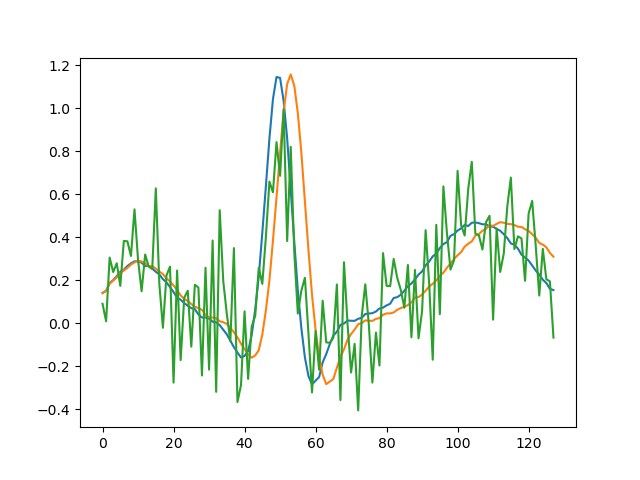

In [20]:
fig, ax = plt.subplots()
ax.plot(X_df['Normal'].values)
ax.plot(X_df['TimeWarping'].values)
ax.plot(X_df['GWN'].values)

In [41]:
detection_MD_sub[anomaly].values

KeyError: (0, 'GWN')